# ДЗ3 · Фреймворк, критик, голосование, план

Голый цикл из ДЗ1, тот же агент на LangGraph, три паттерна недели и потолок на деньги. Все вызовы модели идут через один `httpx.Client` с крючком: токены и `usage.cost` считаются одинаково для цикла и фреймворка.

Полный прогон (дорого, ~40 вопросов × 6–8 конфигураций):

```bash
python hw3.py --eval --limit 40
```

Эта тетрадка читает уже посчитанные артефакты из `artifacts_hw3/` и не гоняет агента заново.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display, Markdown
import hw3

art = hw3.load_artifacts()
table = art["table"]
first = art["first"]
wrong = art["wrong"]
spend = json.loads(Path("artifacts_hw3/spend.json").read_text()) if Path("artifacts_hw3/spend.json").exists() else {"usd": hw3.spent(), "n": 40}
print("конфигураций:", list(table["конфигурация"]) if "конфигурация" in table.columns else list(hw3.RESULTS))
print("вызовов модели (полный eval):", spend.get("model_calls_eval"), "| потрачено $%.3f" % spend["usd"])
table


конфигураций: ['голый цикл, mini', 'LangGraph как есть, mini', 'LangGraph, mini', 'LangGraph + критик, mini', 'голосование 3, mini', 'каскад: 3 голоса mini, иначе Sonnet', 'план + LangGraph, mini', 'LangGraph, Sonnet']
вызовов модели (полный eval): 1619 | потрачено $1.208


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",26/40,0.650,3.6,1965,0.0327,0.0503
1,"LangGraph как есть, mini",20/40,0.500,4.2,2686,0.0399,0.0798
2,"LangGraph, mini",23/40,0.575,3.7,2105,0.0343,0.0597
3,"LangGraph + критик, mini",24/40,0.600,6.3,3773,0.0609,0.1015
4,"голосование 3, mini",26/40,0.650,11.0,6115,0.1009,0.1553
5,"каскад: 3 голоса mini, иначе Sonnet",29/40,0.725,13.5,9150,1.2110,1.6703
6,"план + LangGraph, mini",16/40,0.400,5.3,3092,0.0527,0.1317
7,"LangGraph, Sonnet",30/40,0.750,3.5,4339,1.5836,2.1114


## Счётчик HTTP

In [2]:
pd.DataFrame(hw3.CALLS).head(8)


,tag,model,messages,tools,prompt,completion,cost
0,пустой вопрос: голый цикл,gpt-4o-mini,2,2,176,2,0.000028
1,пустой вопрос: LangGraph,gpt-4o-mini,2,2,176,2,0.000028
2,"пустой вопрос: smolagents, инструменты",gpt-4o-mini,2,3,1125,14,0.000100
3,"пустой вопрос: smolagents, код",gpt-4o-mini,2,0,2132,18,0.000331


## Налог фреймворка на пустом запросе

Один и тот же вопрос `What is 2 + 2?` у голого цикла, LangGraph и двух агентов smolagents. Сравнение первого запроса: сколько токенов и какой системный промпт ушёл в сеть.


In [3]:
empty_tags = [t for t in first if str(t).startswith("пустой")]
rows = []
for tag in empty_tags:
    info = first[tag]
    rows.append({
        "конфигурация": tag,
        "сообщений": info.get("n_messages"),
        "инструментов": info.get("n_tools"),
        "токенов первого запроса": info.get("prompt_tokens_first"),
        "системный промпт, символов": len(info.get("system") or ""),
    })
pd.DataFrame(rows)


,конфигурация,сообщений,инструментов,токенов первого запроса,"системный промпт, символов"
0,пустой вопрос: голый цикл,2,2,176,180
1,пустой вопрос: LangGraph,2,2,176,180
2,"пустой вопрос: smolagents, инструменты",2,3,1125,2500
3,"пустой вопрос: smolagents, код",2,0,2132,2500


In [4]:
def page_find_props(tag):
    params = (first.get(tag) or {}).get("tool_params") or {}
    pf = params.get("page_find") or {}
    return json.dumps(pf.get("properties") or pf, ensure_ascii=False)[:800]

for tag in ["голый цикл, mini", "LangGraph как есть, mini", "LangGraph, mini"]:
    if tag in first:
        print("===", tag, "===")
        print(page_find_props(tag))
        print()


=== голый цикл, mini ===
{"title": {"type": "string", "description": "exact article title, e.g. 2026 in Japan"}, "keywords": {"type": "string", "description": "two to five keywords"}}

=== LangGraph как есть, mini ===
{"title": {"type": "string"}, "keywords": {"type": "string"}}

=== LangGraph, mini ===
{"title": {"description": "exact article title, e.g. 2026 in Japan", "type": "string"}, "keywords": {"description": "two to five keywords", "type": "string"}}



In [5]:
probe = Path("artifacts_hw3/empty_probe.csv")
pd.read_csv(probe, index_col=0) if probe.exists() else "нет empty_probe.csv — прогон ещё идёт"


,вызовов,первый_запрос,всего_токенов,центов
tag,,,,
пустой вопрос: голый цикл,1,176,178,0.0028
пустой вопрос: LangGraph,1,176,178,0.0028
"пустой вопрос: smolagents, инструменты",1,1125,1139,0.0100
"пустой вопрос: smolagents, код",1,2132,2150,0.0331


## Итоговая таблица и картинка

In [6]:
table


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",26/40,0.650,3.6,1965,0.0327,0.0503
1,"LangGraph как есть, mini",20/40,0.500,4.2,2686,0.0399,0.0798
2,"LangGraph, mini",23/40,0.575,3.7,2105,0.0343,0.0597
3,"LangGraph + критик, mini",24/40,0.600,6.3,3773,0.0609,0.1015
4,"голосование 3, mini",26/40,0.650,11.0,6115,0.1009,0.1553
5,"каскад: 3 голоса mini, иначе Sonnet",29/40,0.725,13.5,9150,1.2110,1.6703
6,"план + LangGraph, mini",16/40,0.400,5.3,3092,0.0527,0.1317
7,"LangGraph, Sonnet",30/40,0.750,3.5,4339,1.5836,2.1114


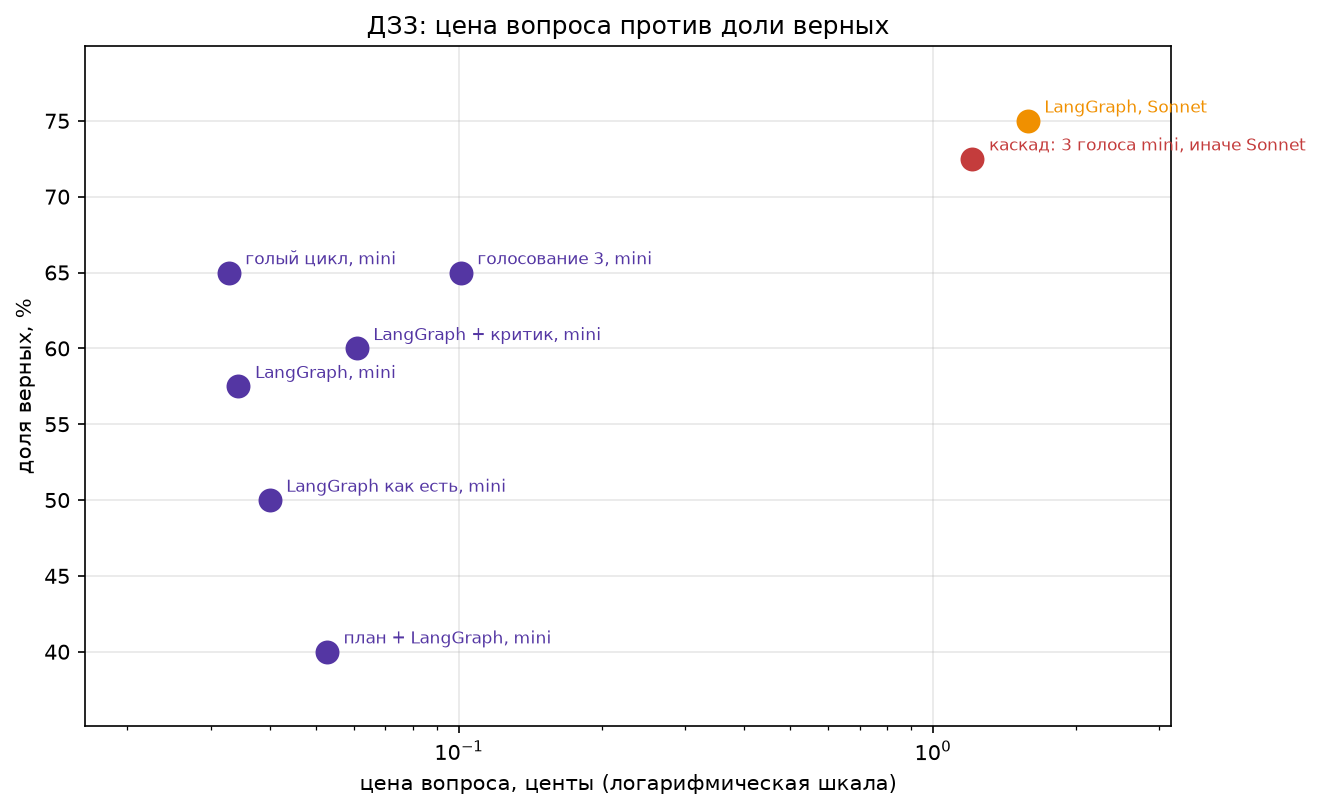

In [7]:
img = Path("img/money_hw3.png")
if img.exists():
    display(Image(filename=str(img)))
else:
    tags = [t for t in hw3.RESULTS]
    if tags:
        hw3.money_chart(tags)
        display(Image(filename="img/money_hw3.png"))


## Критик: исправил против испортил

In [8]:
delta_p = Path("artifacts_hw3/critic_delta.json")
delta = json.loads(delta_p.read_text()) if delta_p.exists() else {}
print("исправил", delta.get("fixed"), "| испортил", delta.get("broken"))
pd.DataFrame(delta.get("details") or [])


исправил 2 | испортил 1


,id,kind,before,after
0,fresh-15,fixed,Mykhailo Fedorov was dismissed as Commander-in...,Oleksandr Syrskyi was dismissed as Commander-i...
1,fresh-21,fixed,I couldn't find any information regarding an a...,Gavin Snider accused Devon Rodriguez of presen...
2,fresh-24,broken,A drought was declared across the whole of Wal...,"In July 2026, the Welsh Government activated ""..."


## Голосование и каскад

In [9]:
print("ушло наверх:", len(art["escalated"]), "из", int(spend.get("n", 40)))
pd.DataFrame({"вопрос": art["escalated"][:12]})


ушло наверх: 26 из 40


,вопрос
0,"What measure came into force in Victoria, Aust..."
1,Who was charged by the FSB in Russia on 29 Jul...
2,How many people were killed in the February 18...
3,What was the title of the art exhibition at Fo...
4,What is the number of children receiving suppo...
5,What is the highest recorded temperature in Ge...
6,What city in Spain experienced a fatal inciden...
7,Who was dismissed as Commander-in-Chief of the...
8,"In ice hockey, which team won their first Walt..."
9,"In spaceflight, what was launched by ISRO on S..."


## Проверка проверки

Десять ответов, которые `is_correct` счёл неверными, для ключевых конфигураций. Читать глазами до выводов про качество.


In [10]:
for tag in ["голый цикл, mini", "LangGraph, mini", "LangGraph + критик, mini",
            "каскад: 3 голоса mini, иначе Sonnet", "план + LangGraph, mini", "LangGraph, Sonnet"]:
    rows = wrong.get(tag) or []
    if not rows:
        continue
    display(Markdown(f"**{tag}** — {len(rows)} из выборки неверных"))
    display(pd.DataFrame(rows))


**голый цикл, mini** — 10 из выборки неверных

,id,эталон,ответ,вопрос
0,fresh-2,Miguel Díaz-Canel,Iran entered negotiations with the Trump admin...,Who entered negotiations with the Trump admini...
1,fresh-6,"4,500",519 people are reported missing in Tibet after...,How many people are reported missing in Tibet ...
2,fresh-15,Oleksandr Syrskyi,I could not find the specific information rega...,Who was dismissed as Commander-in-Chief of the...
3,fresh-21,Gavin Snider,I could not find any information regarding an ...,"In art, which artist accused Devon Rodriguez o..."
4,fresh-23,German Galushchenko,I couldn't find specific information about an ...,"In Ukraine, who was arrested on February 15, 2..."
5,fresh-28,nine,Six people were killed in the mass shooting at...,What was the number of people killed in the ma...
6,fresh-29,43,46 people were killed in the train derailment ...,How many people were killed in the train derai...
7,fresh-31,Aibek Dädebai,The new government of Kazakhstan was formed by...,Who formed the new government of Kazakhstan af...
8,fresh-32,Richard Lewer,No information found.,"Who won the Archibald Prize on May 8, 2026?"
9,fresh-33,Marilyn Gladu,I couldn't find specific information about an ...,Which MP defected from the Conservative Party ...


**LangGraph, mini** — 10 из выборки неверных

,id,эталон,ответ,вопрос
0,fresh-2,Miguel Díaz-Canel,Iran entered negotiations with the Trump admin...,Who entered negotiations with the Trump admini...
1,fresh-6,"4,500",519 people are reported missing in Tibet after...,How many people are reported missing in Tibet ...
2,fresh-12,"700,000",I couldn't find the specific number of childre...,What is the number of children receiving suppo...
3,fresh-14,Ciudad Rodrigo,I could not find specific information about a ...,What city in Spain experienced a fatal inciden...
4,fresh-15,Oleksandr Syrskyi,Mykhailo Fedorov was dismissed as Commander-in...,Who was dismissed as Commander-in-Chief of the...
5,fresh-19,Disney Kids & Family,Disney Branded Television rebranded itself as ...,"In animation, what did Disney Branded Televisi..."
6,fresh-21,Gavin Snider,I couldn't find any information regarding an a...,"In art, which artist accused Devon Rodriguez o..."
7,fresh-23,German Galushchenko,I couldn't find specific information about an ...,"In Ukraine, who was arrested on February 15, 2..."
8,fresh-28,nine,Six people were killed in the mass shooting at...,What was the number of people killed in the ma...
9,fresh-29,43,46 people were killed in the train derailment ...,How many people were killed in the train derai...


**LangGraph + критик, mini** — 10 из выборки неверных

...

,id,эталон,ответ,вопрос
0,fresh-2,Miguel Díaz-Canel,Iran entered negotiations with the Trump admin...,Who entered negotiations with the Trump admini...
1,fresh-6,"4,500",519 people are reported missing in Tibet after...,How many people are reported missing in Tibet ...
2,fresh-13,41.5 °C,"Based on the search results, I was unable to f...",What is the highest recorded temperature in Ge...
3,fresh-17,EOS-05,"Based on my research, I was unable to retrieve...","In spaceflight, what was launched by ISRO on S..."
4,fresh-28,nine,Six people were killed in the mass shooting at...,What was the number of people killed in the ma...
5,fresh-29,43,**46 people** were killed in the train derailm...,How many people were killed in the train derai...
6,fresh-31,Aibek Dädebai,"After the legislative election on August 23, 2...",Who formed the new government of Kazakhstan af...
7,fresh-32,Richard Lewer,I was unable to find the specific winner of th...,"Who won the Archibald Prize on May 8, 2026?"
8,fresh-33,Marilyn Gladu,"Based on my research, I was unable to find a s...",Which MP defected from the Conservative Party ...
9,fresh-36,129,At least 136 people were killed in the earthqu...,How many people were killed in the earthquake ...


**план + LangGraph, mini** — 10 из выборки неверных

,id,эталон,ответ,вопрос
0,fresh-2,Miguel Díaz-Canel,Iran entered negotiations with the Trump admin...,Who entered negotiations with the Trump admini...
1,fresh-3,a strategic partnership agreement,There were no specific details found regarding...,What agreement did Ukraine and Romania sign in...
2,fresh-4,A total fire ban,No specific measures or legislation were ident...,"What measure came into force in Victoria, Aust..."
3,fresh-6,"4,500",519 people are reported missing in Tibet after...,How many people are reported missing in Tibet ...
4,fresh-8,Pavel Durov,No specific individual was reported as charged...,Who was charged by the FSB in Russia on 29 Jul...
5,fresh-10,Twelve,No information found regarding the February 18...,How many people were killed in the February 18...
6,fresh-12,"700,000",I couldn't find specific statistics for the nu...,What is the number of children receiving suppo...
7,fresh-13,41.5 °C,The highest recorded temperature in Germany du...,What is the highest recorded temperature in Ge...
8,fresh-14,Ciudad Rodrigo,The city in Spain that experienced a fatal inc...,What city in Spain experienced a fatal inciden...
9,fresh-17,EOS-05,No information found about ISRO's launch on Se...,"In spaceflight, what was launched by ISRO on S..."


**LangGraph, Sonnet** — 10 из выборки неверных

,id,эталон,ответ,вопрос
0,fresh-2,Miguel Díaz-Canel,"Based on the information found, **Iran** enter...",Who entered negotiations with the Trump admini...
1,fresh-6,"4,500",**519 people** are reported missing in the Tib...,How many people are reported missing in Tibet ...
2,fresh-13,41.5 °C,"Based on the information found, by 27 June 202...",What is the highest recorded temperature in Ge...
3,fresh-17,EOS-05,"Based on my research, I was unable to retrieve...","In spaceflight, what was launched by ISRO on S..."
4,fresh-29,43,**46 people** were killed in the train derailm...,How many people were killed in the train derai...
5,fresh-31,Aibek Dädebai,"After the legislative election on August 23, 2...",Who formed the new government of Kazakhstan af...
6,fresh-32,Richard Lewer,I was unable to find the specific winner of th...,"Who won the Archibald Prize on May 8, 2026?"
7,fresh-33,Marilyn Gladu,"Based on my research, I was unable to find spe...",Which MP defected from the Conservative Party ...
8,fresh-36,129,**136 people** were killed in the earthquake t...,How many people were killed in the earthquake ...
9,fresh-39,Gelida,"The train collision in Spain on January 20, 20...",What was the location of the train collision i...


## Потолок на деньги

In [11]:
limit = json.loads(Path("artifacts_hw3/limit_demo.json").read_text()) if Path("artifacts_hw3/limit_demo.json").exists() else {}
limit


{'question': 'Compare the months of the 2026 Winter Olympics and the 2026 FIFA World Cup, then list three events of each.',
 'answer': 'Model call limits exceeded: run limit (2/2)',
 'model_calls': 2}

## Человек в контуре перед необратимым инструментом

In [12]:
hitl = json.loads(Path("artifacts_hw3/hitl_demo.json").read_text()) if Path("artifacts_hw3/hitl_demo.json").exists() else {}
hitl


{'question': 'Find who won the 2026 FIFA World Cup final and email a one-line summary to boss@example.com',
 'steps': [{'stage': 'interrupt',
   'action_requests': [{'name': 'send_summary',
     'args': {'to': 'boss@example.com',
      'text': 'Spain won the 2026 FIFA World Cup final against Argentina.'},
     'description': "Tool execution requires approval\n\nTool: send_summary\nArgs: {'to': 'boss@example.com', 'text': 'Spain won the 2026 FIFA World Cup final against Argentina.'}"}]},
  {'stage': 'reject_then_interrupt',
   'action_requests': [{'name': 'send_summary',
     'args': {'to': 'boss@example.com',
      'text': 'Spain won the 2026 FIFA World Cup final against Argentina with a score of 2-0.'},
     'description': "Tool execution requires approval\n\nTool: send_summary\nArgs: {'to': 'boss@example.com', 'text': 'Spain won the 2026 FIFA World Cup final against Argentina with a score of 2-0.'}"}]},
  {'stage': 'approve',
   'answer': 'I found that Spain won the 2026 FIFA World C